# RQ2 - LSTM
Direct multi-horizon LSTM forecaster of the hourly charging demand of a site (H = 1 and H = 24).

Inputs: (a) a 168-hour window of four dynamic channels ending at hour t-H (load, vehicles plugged in, vehicles still charging, arrivals), and (b) the 16 common features shared by every forecasting model (lag and rolling load features, vehicle-state features, calendar features), concatenated after the recurrent layers.
Split: Train to 31/10/2019, Val to 15/01/2020, Test 16/01/2020 to the end of data (one single block).
Hyperparameters are tuned with Optuna (TPE) on the Validation MAE. Run 1: fit on Train with early stopping on Val, evaluate on Test. Run 2: refit on Train+Val with the epoch count found in run 1, evaluate on Test. The final prediction of each run is the mean of 3 seeds.
Training uses the GPU.

In [1]:
MODEL_TAG, MODEL_NAME = 'lstm', 'LSTM'

In [2]:
# ====================== SHARED CONFIG (identical in every RQ2/RQ3 notebook) ======================
import os, sys, glob, json, random, warnings, subprocess, time, hashlib, platform, base64, gzip, io
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.metrics import mean_absolute_error, mean_squared_error
pd.set_option('display.width', 250, 'display.max_columns', None, 'display.max_rows', 500)

FAST_MODE   = False        # True = smoke test only
SEED        = 42
SITES       = [1, 2]       # one hourly series (and one model) per site; site 19 is dropped (too sparse)
HORIZONS    = [1, 24]      # H=1 next hour, H=24 one day ahead (direct strategy)

# ---- Split requested by the author: Train -> 31/10/2019, Val -> 15/01/2020, Test = 16/01/2020 -> end of data ----
TRAIN_END   = '2019-10-31 23:00'
VAL_END     = '2020-01-15 23:00'
# Two training protocols:
#   run1 : fit on Train, early-stop / select on Val, evaluate on Test        (train - val - test)
#   run2 : refit on Train+Val with the settings chosen in run1, evaluate on Test   (train(train+val) - test)

MAX_LOOKBACK = 168         # longest history window (hours) any model may read
WARMUP_H     = 24 * 28     # first 4 weeks of each series are never targets (672 h of history needed by seasonal_mean_4w)
GAP_DAYS     = 7           # >= 7 consecutive hours-days with zero energy = data outage, not demand
POST_GAP_H   = 24 * 28     # after every outage the next 4 weeks are not targets (lags would read the artificial zeros)
MAPE_MIN     = 0.5         # kWh; MAPE/sMAPE only on hours with at least this load
N_BOOT       = 1000
BLOCK_H      = 24 * 7
if FAST_MODE: N_BOOT = 100
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

# ---- The 16 common features (CFV) used by EVERY forecasting model ----
FEATS_COMMON = ['lag_H', 'lag_D', 'lag_168', 'roll_mean_24', 'roll_max_24', 'seasonal_mean_4w',
                'n_plugged_lagH', 'n_charging_lagH', 'n_arrivals_lagH', 'charging_share_lagH',
                'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_holiday']
assert len(FEATS_COMMON) == 16
FEATS_HASH = hashlib.md5('|'.join(FEATS_COMMON).encode()).hexdigest()[:10]
CAL = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_holiday']
HIST_COLS = ['y_s', 'plug_s', 'chg_s', 'arr_s']          # 4 dynamic channels for recurrent nets

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
try:
    import optuna
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'optuna'], check=True); import optuna
from optuna.importance import get_param_importances
optuna.logging.set_verbosity(optuna.logging.WARNING)
keras.utils.set_random_seed(SEED)
GPUS = tf.config.list_physical_devices('GPU'); GPU = bool(GPUS)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__, '| Optuna', optuna.__version__, '| GPUs:', GPUS)
if os.path.exists('/kaggle/working') and not FAST_MODE:
    assert GPU, 'This notebook must train on GPU: set Accelerator to GPU (P100 or T4) in Kaggle settings.'
N_COV = len(FEATS_COMMON); N_HIST = len(HIST_COLS)

TensorFlow 2.20.0 | Keras 3.13.2 | Optuna 5.0.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
# ---------- Output folder + data file ----------
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else './outputs_' + MODEL_TAG
FIG_DIR = os.path.join(OUT_DIR, 'figures'); os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, f'{MODEL_TAG}_{name}.png'), dpi=140, bbox_inches='tight'); plt.show()
def resolve_data():
    pats = ['/kaggle/input/**/acn_data*.xlsx', '/kaggle/input/**/acn*.xlsx', './acn*.xlsx', '/mnt/user-data/uploads/**/acn*.xlsx']
    for p in pats:
        hits = sorted(glob.glob(p, recursive=True))
        if hits: return hits[0]
    raise FileNotFoundError('acn*.xlsx not found. Add the ACN dataset as notebook input.')
DATA_PATH = resolve_data()
print('Model:', MODEL_NAME, '| data:', DATA_PATH, '| python', sys.version.split()[0])

# ---------- Read + clean sessions ----------
try: raw = pd.read_excel(DATA_PATH, sheet_name='full_data')
except ValueError: raw = pd.read_excel(DATA_PATH)
for c in ['connectionTime', 'disconnectTime', 'doneChargingTime']: raw[c] = pd.to_datetime(raw[c])
sess = raw.drop_duplicates(['stationID', 'connectionTime']).copy()
sess['done'] = sess['doneChargingTime'].clip(upper=sess['disconnectTime'])
sess = sess[(sess.kWhDelivered > 0) & (sess.disconnectTime > sess.connectionTime)]
sess = sess[sess.siteID.isin(SITES)].reset_index(drop=True)
print(f'sessions after cleaning (sites {SITES}): {len(sess):,} / raw {len(raw):,}')

# ---------- Hourly load series per site ----------
def spread_energy(s):
    c = s.connectionTime.values.astype('datetime64[s]'); e = s.done.values.astype('datetime64[s]')
    e = np.maximum(e, c + np.timedelta64(60, 's'))
    c0 = c.astype('datetime64[h]'); e0 = (e - np.timedelta64(1, 's')).astype('datetime64[h]')
    n = ((e0 - c0) // np.timedelta64(1, 'h')).astype(int) + 1
    idx = np.repeat(np.arange(len(s)), n)
    k = np.arange(n.sum()) - np.repeat(np.cumsum(n) - n, n)
    hs = c0[idx] + k.astype('timedelta64[h]'); he = hs + np.timedelta64(1, 'h')
    ov = (np.minimum(e[idx], he) - np.maximum(c[idx], hs)) / np.timedelta64(1, 's')
    tot = ((e - c) / np.timedelta64(1, 's'))[idx]
    return pd.Series(s.kWhDelivered.values[idx] * ov / tot, index=pd.DatetimeIndex(hs)).groupby(level=0).sum()

def hourly_site(s):
    y = spread_energy(s)
    grid = pd.date_range(s.connectionTime.min().floor('h'), s.done.max().ceil('h'), freq='h', name='time')
    out = pd.DataFrame(index=grid); out['y'] = y.reindex(grid).fillna(0.0)
    ends = (grid + pd.Timedelta(hours=1)).values
    conn = np.sort(s.connectionTime.values); disc = np.sort(s.disconnectTime.values); done = np.sort(s.done.values)
    out['n_plugged_end']  = np.searchsorted(conn, ends, 'right') - np.searchsorted(disc, ends, 'right')
    out['n_charging_end'] = np.searchsorted(conn, ends, 'right') - np.searchsorted(done, ends, 'right')
    out['n_arrivals'] = pd.Series(1, index=s.connectionTime.dt.floor('h')).groupby(level=0).sum().reindex(grid).fillna(0).values
    return out

hol = USFederalHolidayCalendar().holidays('2018-01-01', '2021-12-31')
def add_calendar(Hs):
    ix = Hs.index
    Hs['hour_sin'] = np.sin(2*np.pi*ix.hour/24);     Hs['hour_cos'] = np.cos(2*np.pi*ix.hour/24)
    Hs['dow_sin']  = np.sin(2*np.pi*ix.dayofweek/7); Hs['dow_cos']  = np.cos(2*np.pi*ix.dayofweek/7)
    Hs['is_weekend'] = (ix.dayofweek >= 5).astype(float)
    Hs['is_holiday'] = ix.normalize().isin(hol).astype(float)     # US federal calendar, NOT the file's is_holiday column
    return Hs

T_END, V_END = pd.Timestamp(TRAIN_END), pd.Timestamp(VAL_END)
HOURLY, GAP_RUNS, SCALE, THR90, MASE_SCALE = {}, {}, {}, {}, {}
for sid in SITES:
    s = sess[sess.siteID == sid]
    Hs = hourly_site(s)
    assert abs(Hs.y.sum() - s.kWhDelivered.sum()) < 1e-3, 'kWh not conserved'
    inactive = (Hs.y == 0); grp = (inactive != inactive.shift()).cumsum()
    Hs['in_gap'] = inactive & (inactive.groupby(grp).transform('size') >= GAP_DAYS * 24)
    _g = (Hs.in_gap != Hs.in_gap.shift()).cumsum()
    GAP_RUNS[sid] = [(g.index.min(), g.index.max()) for _, g in Hs[Hs.in_gap].groupby(_g[Hs.in_gap])]
    post = np.zeros(len(Hs), bool)
    for a, b in GAP_RUNS[sid]:
        j = Hs.index.get_loc(b); post[j + 1: j + 1 + POST_GAP_H] = True
    Hs['post_gap'] = post
    Hs['valid'] = (~Hs.in_gap.values) & (~post) & (np.arange(len(Hs)) >= WARMUP_H)   # identical target hours for every model
    Hs = add_calendar(Hs)
    tr_ok = (Hs.index <= T_END) & Hs.valid.values
    SCALE[sid] = {c: max(float(np.quantile(Hs.loc[tr_ok, c], .99)), 1e-6) for c in ['y', 'n_plugged_end', 'n_charging_end', 'n_arrivals']}
    Hs['y_s'] = Hs.y / SCALE[sid]['y']; Hs['plug_s'] = Hs.n_plugged_end / SCALE[sid]['n_plugged_end']
    Hs['chg_s'] = Hs.n_charging_end / SCALE[sid]['n_charging_end']; Hs['arr_s'] = Hs.n_arrivals / SCALE[sid]['n_arrivals']
    THR90[sid] = float(np.quantile(Hs.loc[tr_ok, 'y'], .90))
    d24 = (Hs.y - Hs.y.shift(24)).abs()[tr_ok & Hs.valid.shift(24, fill_value=False).values].dropna()
    MASE_SCALE[sid] = float(d24.mean())
    HOURLY[sid] = Hs
    print(f'site {sid}: {len(Hs):,} h | {Hs.index.min()} -> {Hs.index.max()} | valid target hours {int(Hs.valid.sum()):,} | P90(train)={THR90[sid]:.2f} kWh')
    for a, b in GAP_RUNS[sid]: print(f'    outage {a} -> {b} ({(b-a).days+1} days)')

# ---------- Split (time based) ----------
def split_of(t):
    t = np.asarray(t)
    return np.select([t <= T_END, t <= V_END], ['train', 'val'], default='test')
def target_index(site): return np.flatnonzero(HOURLY[site].valid.values)

_rows = []
for sid in SITES:
    ti = target_index(sid); spl = split_of(HOURLY[sid].index.values[ti])
    for nm in ['train', 'val', 'test']:
        m = spl == nm
        _rows.append(dict(site=sid, split=nm, n_target_hours=int(m.sum()), first=HOURLY[sid].index[ti][m].min(), last=HOURLY[sid].index[ti][m].max()))
SPLIT_TBL = pd.DataFrame(_rows).set_index(['site', 'split']); print(SPLIT_TBL.to_string())
BENCH_FINGERPRINT = hashlib.md5('|'.join(map(str, [SITES, HORIZONS, TRAIN_END, VAL_END, MAX_LOOKBACK, WARMUP_H, GAP_DAYS,
                                  POST_GAP_H, MAPE_MIN, FEATS_HASH, SEED])).encode()).hexdigest()[:12]
print('BENCHMARK FINGERPRINT =', BENCH_FINGERPRINT, '| features hash =', FEATS_HASH)

# ---------- 16 common features ----------
def build_common_features(Hs, h):
    """16 columns; every value uses information up to hour t-h only, or is a deterministic function of the calendar."""
    y = Hs.y; D = 24 if h < 24 else 48; f = pd.DataFrame(index=Hs.index)
    f['lag_H'] = y.shift(h); f['lag_D'] = y.shift(D); f['lag_168'] = y.shift(168)
    ys = y.shift(h)
    f['roll_mean_24'] = ys.rolling(24).mean(); f['roll_max_24'] = ys.rolling(24).max()
    f['seasonal_mean_4w'] = pd.concat([y.shift(168 * k) for k in range(1, 5)], axis=1).mean(axis=1)
    f['n_plugged_lagH'] = Hs.n_plugged_end.shift(h); f['n_charging_lagH'] = Hs.n_charging_end.shift(h)
    f['n_arrivals_lagH'] = Hs.n_arrivals.shift(h)
    f['charging_share_lagH'] = (f.n_charging_lagH / f.n_plugged_lagH.replace(0, np.nan)).fillna(0.0)
    for c in CAL: f[c] = Hs[c]
    return f[FEATS_COMMON]

def scale_features(X, site):
    """Same definition, scaled for neural nets (load features / P99(y); count features / P99(count); calendar unchanged)."""
    Z = X.copy(); sy = SCALE[site]['y']
    for c in ['lag_H', 'lag_D', 'lag_168', 'roll_mean_24', 'roll_max_24', 'seasonal_mean_4w']: Z[c] = Z[c] / sy
    Z['n_plugged_lagH'] /= SCALE[site]['n_plugged_end']; Z['n_charging_lagH'] /= SCALE[site]['n_charging_end']
    Z['n_arrivals_lagH'] /= SCALE[site]['n_arrivals']
    return Z.values.astype('float32')

def make_data(site, h, sequences=False):
    Hs = HOURLY[site]; tgt = target_index(site); spl = split_of(Hs.index[tgt]); L = MAX_LOOKBACK
    f = build_common_features(Hs, h)
    if sequences:
        S = Hs[HIST_COLS].values.astype('float32'); Wv = sliding_window_view(S, L, axis=0).swapaxes(1, 2)
    def pack(sel):
        X = f.iloc[sel]
        assert not X.isna().any().any(), 'NaN in features'
        d = dict(idx=sel, X=X, Xs=scale_features(X, site), y=Hs.y.values[sel], y_s=Hs.y_s.values[sel].astype('float32'))
        if sequences: d['hist'] = Wv[sel - h - L + 1].copy()
        return d
    D = {n: pack(tgt[spl == n]) for n in ['train', 'val', 'test']}
    D['dev'] = pack(tgt[np.isin(spl, ['train', 'val'])])
    return D

# ---------- Evaluation library ----------
def pred_frame(site, h, run, split, idx, pred):
    Hs = HOURLY[site]
    return pd.DataFrame({'time': Hs.index[idx], 'site': site, 'horizon': h, 'run': run, 'split': split,
                         'actual': Hs.y.values[idx], 'pred': np.clip(np.asarray(pred, float), 0, None)})

def hourly_stats(d, thr):
    a, p = d.actual.values, d.pred.values; e = p - a; m = a >= MAPE_MIN
    ape = np.where(m, np.abs(e) / np.where(m, a, 1.0), 0.0); sape = np.where(m, 2 * np.abs(e) / np.maximum(a + p, 1e-9), 0.0)
    return np.column_stack([np.ones(len(a)), a, a**2, p, p**2, a*p, np.abs(e), e, e**2, m.astype(float), ape, sape,
                            ((p >= thr) & (a >= thr)).astype(float), (p >= thr).astype(float), (a >= thr).astype(float)])
def make_hourly_fn(scale):
    def fn(s):
        n, sa, saa, sp, spp, sap, sae, se, see, nm, sape, ssape, tp, npp, nap = [s[:, i] for i in range(15)]
        with np.errstate(divide='ignore', invalid='ignore'):
            sst = saa - sa**2 / n; cv = sap - sa * sp / n; vp = spp - sp**2 / n
            return {'MAE': sae / n, 'RMSE': np.sqrt(see / n), 'R2': 1 - see / sst, 'MAPE_%': 100 * sape / nm,
                    'sMAPE_%': 100 * ssape / nm, 'WAPE_%': 100 * sae / sa, 'MASE': sae / n / scale, 'Bias_kWh': se / n,
                    'Pearson_r': cv / np.sqrt(sst * vp), 'P90_precision': tp / npp, 'P90_recall': tp / nap, 'P90_F1': 2 * tp / (npp + nap)}
    return fn
def daily_peaks(d):
    g = d.groupby(d.index.normalize()); ia, ip = g.actual.idxmax(), g.pred.idxmax()
    pk = pd.DataFrame({'act_peak': g.actual.max(), 'pred_peak': g.pred.max(), 'act_h': ia.dt.hour, 'pred_h': ip.dt.hour})
    return pk[pk.act_peak > 0]
def peak_stats(pk):
    a = pk.act_peak.values; e = (pk.pred_peak - pk.act_peak).values
    dh = (pk.pred_h - pk.act_h).abs().values; dh = np.minimum(dh, 24 - dh)
    return np.column_stack([np.ones(len(a)), a, a**2, np.abs(e), e, e**2, (dh <= 1).astype(float)])
def peak_fn(s):
    n, sa, saa, sae, se, see, hit = [s[:, i] for i in range(7)]
    with np.errstate(divide='ignore', invalid='ignore'):
        return {'Peak_MAE': sae / n, 'Peak_WAPE_%': 100 * sae / sa, 'Peak_Bias_%': 100 * se / sa, 'PeakHour_hit_pm1h_%': 100 * hit / n}
def _boot(S, fn, block, rng):
    n = len(S)
    if n / block < 8: block = max(1, block // 7)
    B = np.add.reduceat(S, np.arange(0, n, block), axis=0)
    idx = rng.integers(0, len(B), size=(N_BOOT, len(B)))
    boot = fn(B[idx].sum(axis=1)); point = fn(S.sum(axis=0, keepdims=True)); out = {}
    for k in point:
        b = boot[k][np.isfinite(boot[k])]; ok = len(b) > 2
        out[k] = (float(point[k][0]), float(b.std(ddof=1)) if ok else np.nan)
    return out
def evaluate_all(PRED, seed=SEED):
    rng = np.random.default_rng(seed); rows = []
    for (run, site, h), g in PRED.groupby(['run', 'site', 'horizon']):
        g = g.sort_values('time').set_index('time'); hfn = make_hourly_fn(MASE_SCALE[site])
        for name, d in {'Train': g[g.split == 'train'], 'Val': g[g.split == 'val'], 'Test': g[g.split == 'test']}.items():
            if len(d) < 48: continue
            res = _boot(hourly_stats(d, THR90[site]), hfn, BLOCK_H, rng); pk = daily_peaks(d)
            resp = _boot(peak_stats(pk), peak_fn, 7, rng) if len(pk) >= 8 else {}
            for src in (res, resp):
                for k, v in src.items():
                    rows.append(dict(run=run, site=site, horizon=h, group=name, metric=k, value=v[0], SE=v[1], n_hours=len(d)))
    return pd.DataFrame(rows)
MAIN = ['MAE', 'RMSE', 'R2', 'WAPE_%', 'MASE', 'Bias_kWh', 'P90_F1', 'Peak_MAE']

def standard_report(PRED, extra_json=None):
    """Save predictions + metrics + standard figures; print compact Test tables for both runs."""
    PRED = PRED.sort_values(['run', 'site', 'horizon', 'time']).reset_index(drop=True)
    PRED.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_predictions.csv'), index=False)
    RES = evaluate_all(PRED); RES.insert(0, 'model', MODEL_NAME)
    RES.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_results_long.csv'), index=False)
    T = RES[RES.group.isin(['Val', 'Test']) & RES.metric.isin(MAIN)]
    W = T.pivot_table(index=['run', 'site', 'horizon', 'group'], columns='metric', values='value')[[m for m in MAIN if m in T.metric.unique()]]
    W.to_csv(os.path.join(OUT_DIR, f'{MODEL_TAG}_results_wide.csv'))
    print(f'===== {MODEL_NAME}: Val / Test metrics =====\n', W.round(4).to_string())
    # ---- figures ----
    runs = [r for r in ['run2', 'run1'] if r in PRED.run.unique()]
    r0 = runs[0]; fig, axs = plt.subplots(len(SITES), len(HORIZONS), figsize=(7 * len(HORIZONS), 3.4 * len(SITES)), squeeze=False)
    for i, site in enumerate(SITES):
        for j, h in enumerate(HORIZONS):
            g = PRED[(PRED.run == r0) & (PRED.site == site) & (PRED.horizon == h) & (PRED.split == 'test')].set_index('time')
            g = g[g.index >= g.index.max() - pd.Timedelta(days=14)]
            axs[i, j].plot(g.index, g.actual, color='#444', lw=1.1, label='Actual'); axs[i, j].plot(g.index, g.pred, color='#D55E00', lw=1.1, label='Forecast')
            axs[i, j].set(title=f'{MODEL_NAME} | site {site} | H={h}: last 14 test days', ylabel='kWh per hour'); axs[i, j].legend(fontsize=7)
            axs[i, j].tick_params(axis='x', rotation=20, labelsize=7)
    plt.tight_layout(); savefig('F1_forecast_window')
    fig, axs = plt.subplots(len(SITES), len(HORIZONS), figsize=(4.2 * len(HORIZONS), 3.8 * len(SITES)), squeeze=False)
    for i, site in enumerate(SITES):
        for j, h in enumerate(HORIZONS):
            g = PRED[(PRED.run == r0) & (PRED.site == site) & (PRED.horizon == h) & (PRED.split == 'test')]
            axs[i, j].scatter(g.actual, g.pred, s=4, alpha=.25, color='#0072B2'); m = max(g.actual.max(), g.pred.max())
            axs[i, j].plot([0, m], [0, m], 'k--', lw=.8); axs[i, j].set(title=f'site {site} | H={h}', xlabel='Actual kWh', ylabel='Forecast kWh')
    plt.suptitle(f'{MODEL_NAME}: actual vs forecast (Test)', y=1.02); plt.tight_layout(); savefig('F2_scatter')
    fig, axs = plt.subplots(1, len(SITES), figsize=(5.5 * len(SITES), 3.4), squeeze=False)
    for i, site in enumerate(SITES):
        for h, c in zip(HORIZONS, ['#009E73', '#CC79A7']):
            g = PRED[(PRED.run == r0) & (PRED.site == site) & (PRED.horizon == h) & (PRED.split == 'test')]
            e = (g.actual - g.pred).abs().groupby(g.time.dt.hour).mean(); axs[0, i].plot(e.index, e.values, 'o-', ms=3, color=c, label=f'H={h}')
        axs[0, i].set(title=f'site {site}: MAE by hour of day (Test)', xlabel='Hour', ylabel='MAE (kWh)'); axs[0, i].legend(fontsize=7)
    plt.tight_layout(); savefig('F3_error_by_hour')
    if extra_json is not None:
        S = {'model': MODEL_NAME, 'tag': MODEL_TAG, 'fingerprint': BENCH_FINGERPRINT, 'features': FEATS_COMMON,
             'split': {'TRAIN_END': TRAIN_END, 'VAL_END': VAL_END, 'TEST': '2020-01-16 -> end of data'}, **extra_json}
        with open(os.path.join(OUT_DIR, f'{MODEL_TAG}_best_hyperparameters.json'), 'w') as f: json.dump(S, f, indent=2, default=str)
    return RES, W
print('core ready')

Model: LSTM | data: /kaggle/input/datasets/quangthai0406/acn-cleaned-sessions-dap391m/acn_data(cleaned).xlsx | python 3.13.15
sessions after cleaning (sites [1, 2]): 58,687 / raw 60,105
site 1: 26,512 h | 2018-09-05 04:00:00 -> 2021-09-13 19:00:00 | valid target hours 16,962 | P90(train)=81.43 kWh
    outage 2020-03-31 13:00:00 -> 2021-02-01 03:00:00 (307 days)
    outage 2021-07-21 10:00:00 -> 2021-07-28 16:00:00 (8 days)
site 2: 29,703 h | 2018-04-25 04:00:00 -> 2021-09-13 18:00:00 | valid target hours 20,994 | P90(train)=43.06 kWh
    outage 2020-03-31 12:00:00 -> 2021-02-01 08:00:00 (307 days)
            n_target_hours               first                last
site split                                                        
1    train            9452 2018-10-03 04:00:00 2019-10-31 23:00:00
     val              1824 2019-11-01 00:00:00 2020-01-15 23:00:00
     test             5686 2020-01-16 00:00:00 2021-09-13 19:00:00
2    train           12644 2018-05-23 04:00:00 2019-10-31 23

In [5]:
def space_rnn(t):
    p = dict(lookback=t.suggest_categorical('lookback', [24, 48, 72, 168]),
             n_layers=t.suggest_int('n_layers', 1, 2),
             units_0=t.suggest_int('units_0', 32, 192, step=32),
             dropout=t.suggest_float('dropout', 0.0, 0.5, step=0.1),
             bidirectional=t.suggest_categorical('bidirectional', [False, True]),
             dense_units=t.suggest_int('dense_units', 16, 128, step=16),
             learning_rate=t.suggest_float('learning_rate', 1e-4, 5e-3, log=True),
             weight_decay=t.suggest_float('weight_decay', 1e-8, 1e-2, log=True),
             loss=t.suggest_categorical('loss', ['mse', 'huber']),
             batch_size=t.suggest_categorical('batch_size', [64, 128, 256]))
    if p['n_layers'] == 2: p['units_1'] = t.suggest_int('units_1', 32, 192, step=32)
    return p

def build_rnn(kind, p):
    """kind = 'lstm' or 'gru'. Inputs: hist (168 x 4 dynamic channels, ending at t-H) and cov (the 16 common features)."""
    lb = int(p['lookback']); units = [int(p['units_0'])] + ([int(p['units_1'])] if int(p['n_layers']) == 2 else [])
    hist_in = keras.Input((MAX_LOOKBACK, N_HIST), name='hist'); cov_in = keras.Input((N_COV,), name='cov')
    x = layers.Cropping1D((MAX_LOOKBACK - lb, 0))(hist_in)
    for k, u in enumerate(units):
        cell = (layers.LSTM if kind == 'lstm' else layers.GRU)(u, return_sequences=(k < len(units) - 1))   # no recurrent_dropout: keeps the cuDNN kernel
        x = layers.Bidirectional(cell)(x) if p.get('bidirectional') else cell(x)
        if p['dropout'] > 0: x = layers.Dropout(p['dropout'])(x)
    x = layers.Concatenate()([x, cov_in])
    x = layers.Dense(int(p['dense_units']), activation='relu')(x)
    if p['dropout'] > 0: x = layers.Dropout(p['dropout'])(x)
    m = keras.Model([hist_in, cov_in], layers.Dense(1, name='load')(x))
    loss = 'mse' if p['loss'] == 'mse' else keras.losses.Huber(delta=1.0)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=float(p['learning_rate']), clipnorm=1.0, weight_decay=float(p.get('weight_decay', 0.0))),
              loss=loss, metrics=['mae'])
    return m

def fit_rnn(kind, p, tr, va, epochs, patience, seed, final=False):
    keras.backend.clear_session(); keras.utils.set_random_seed(seed)
    m = build_rnn(kind, p); xtr = {'hist': tr['hist'], 'cov': tr['Xs']}; bs = int(p['batch_size'])
    if va is None:
        hist = m.fit(xtr, tr['y_s'], epochs=epochs, batch_size=bs, verbose=0)
    else:
        cb = [keras.callbacks.EarlyStopping('val_mae', patience=patience, restore_best_weights=True)]
        if final: cb.append(keras.callbacks.ReduceLROnPlateau('val_mae', factor=.5, patience=max(2, patience // 3), min_lr=1e-6))
        hist = m.fit(xtr, tr['y_s'], validation_data=({'hist': va['hist'], 'cov': va['Xs']}, va['y_s']), epochs=epochs,
                     batch_size=bs, callbacks=cb, verbose=0)
    return m, hist

def pred_rnn(m, d, site):
    return np.clip(m.predict({'hist': d['hist'], 'cov': d['Xs']}, batch_size=1024, verbose=0).ravel() * SCALE[site]['y'], 0, None)

def tune_rnn(kind, site, h, n_trials, tune_epochs, tune_patience):
    D = DATA[(site, h)]
    def obj(t):
        p = space_rnn(t); m, hist = fit_rnn(kind, p, D['train'], D['val'], tune_epochs, tune_patience, SEED)
        v = np.array(hist.history['val_mae']); t.set_user_attr('best_epoch', int(v.argmin()) + 1)
        keras.backend.clear_session(); return float(v.min()) * SCALE[site]['y']
    st = optuna.create_study(direction='minimize', study_name=f'{kind}_s{site}_H{h}', sampler=optuna.samplers.TPESampler(seed=SEED + 10 * site + h, multivariate=True, group=True))
    st.optimize(obj, n_trials=n_trials, show_progress_bar=False); return st

In [6]:
N_TRIALS, TUNE_EPOCHS, TUNE_PATIENCE, FINAL_EPOCHS, PATIENCE, N_SEEDS = 20, 25, 5, 150, 15, 3
if FAST_MODE: N_TRIALS, TUNE_EPOCHS, TUNE_PATIENCE, FINAL_EPOCHS, PATIENCE, N_SEEDS = 2, 2, 1, 3, 2, 1
DATA = {}
for site in SITES:
    for h in HORIZONS:
        DATA[(site, h)] = D = make_data(site, h, sequences=True)
        print(f"site {site} | H={h:>2} | " + ' | '.join(f"{n}: {len(D[n]['y']):6,d}" for n in ['train', 'val', 'test', 'dev']), '| hist', D['train']['hist'].shape[1:], '| cov', D['train']['Xs'].shape[1:])

site 1 | H= 1 | train:  9,452 | val:  1,824 | test:  5,686 | dev: 11,276 | hist (168, 4) | cov (16,)
site 1 | H=24 | train:  9,452 | val:  1,824 | test:  5,686 | dev: 11,276 | hist (168, 4) | cov (16,)
site 2 | H= 1 | train: 12,644 | val:  1,824 | test:  6,526 | dev: 14,468 | hist (168, 4) | cov (16,)
site 2 | H=24 | train: 12,644 | val:  1,824 | test:  6,526 | dev: 14,468 | hist (168, 4) | cov (16,)


In [7]:
STUDIES, ROWS = {}, []
for site in SITES:
    for h in HORIZONS:
        t0 = time.time(); st = tune_rnn('lstm', site, h, N_TRIALS, TUNE_EPOCHS, TUNE_PATIENCE); STUDIES[(site, h)] = st
        print(f'site {site} | H={h} | best Val MAE {st.best_value:.4f} kWh/h | {(time.time()-t0)/60:.1f} min | {st.best_params}')
        for tr in st.trials:
            if tr.value is not None: ROWS.append(dict(site=site, horizon=h, trial=tr.number, val_mae=tr.value, best_epoch=tr.user_attrs.get('best_epoch'), **tr.params))
TRIALS = pd.DataFrame(ROWS).sort_values(['site', 'horizon', 'val_mae']); TRIALS.to_csv(os.path.join(OUT_DIR, 'lstm_tuning_trials.csv'), index=False)
print(TRIALS.groupby(['site', 'horizon']).head(3).round(4).to_string())

I0000 00:00:1792921277.207588      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792921277.210977      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


site 1 | H=1 | best Val MAE 2.9852 kWh/h | 9.9 min | {'lookback': 24, 'n_layers': 2, 'units_0': 128, 'dropout': 0.2, 'bidirectional': True, 'dense_units': 112, 'learning_rate': 0.0034977462857120802, 'weight_decay': 0.005475708314604606, 'loss': 'mse', 'batch_size': 128, 'units_1': 128}
site 1 | H=24 | best Val MAE 7.5691 kWh/h | 13.9 min | {'lookback': 168, 'n_layers': 2, 'units_0': 64, 'dropout': 0.30000000000000004, 'bidirectional': True, 'dense_units': 80, 'learning_rate': 0.0015857199479626805, 'weight_decay': 1.4875889582527463e-06, 'loss': 'mse', 'batch_size': 128, 'units_1': 64}
site 2 | H=1 | best Val MAE 2.1651 kWh/h | 14.3 min | {'lookback': 72, 'n_layers': 1, 'units_0': 128, 'dropout': 0.2, 'bidirectional': False, 'dense_units': 112, 'learning_rate': 0.0012640487905670626, 'weight_decay': 3.805257307355401e-05, 'loss': 'huber', 'batch_size': 256}
site 2 | H=24 | best Val MAE 4.1071 kWh/h | 14.5 min | {'lookback': 48, 'n_layers': 2, 'units_0': 64, 'dropout': 0.2, 'bidirectio

site 1 | H=1 | run1 epochs [50, 39, 32] | run2 epochs 45 | params 561,121
site 1 | H=24 | run1 epochs [33, 27, 30] | run2 epochs 34 | params 145,825
site 2 | H=1 | run1 epochs [34, 54, 39] | run2 epochs 45 | params 84,449
site 2 | H=24 | run1 epochs [12, 11, 9] | run2 epochs 13 | params 554,113
===== LSTM: Val / Test metrics =====
 metric                      MAE     RMSE      R2   WAPE_%    MASE  Bias_kWh  P90_F1  Peak_MAE
run  site horizon group                                                                      
run1 1    1       Test   2.5392   4.7927  0.9620  17.3648  0.1875    0.4798  0.9398    5.0053
                  Val    2.7654   4.7216  0.9826  12.1199  0.2042   -0.1667  0.9451    4.5058
          24      Test   7.3396  12.8828  0.7254  50.1933  0.5420    4.1350  0.7768   16.1261
                  Val    7.2723  13.0628  0.8670  31.8724  0.5371   -0.3213  0.8646   14.0135
     2    1       Test   1.5946   2.5592  0.8766  45.6358  0.2027    0.5668  0.8515    3.1541
        

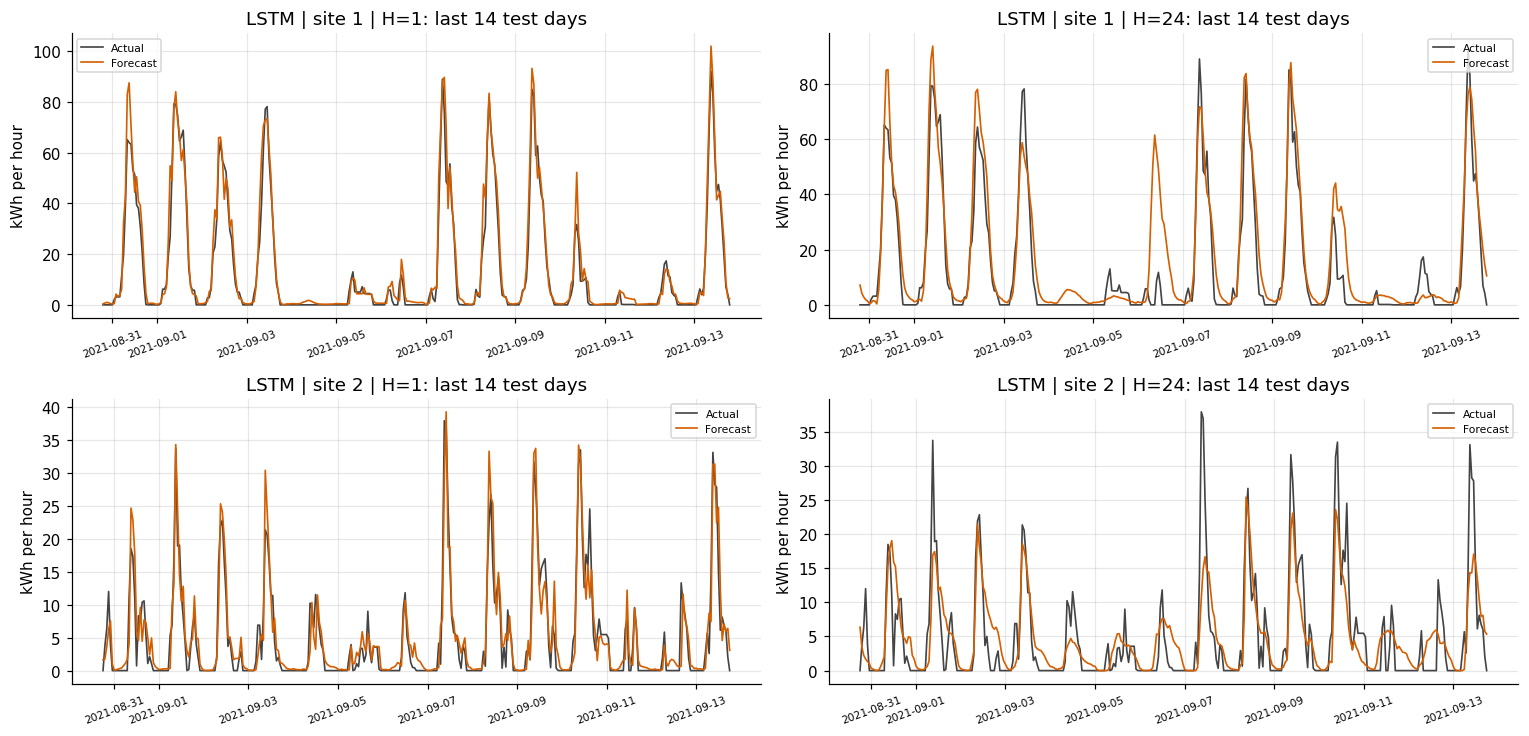

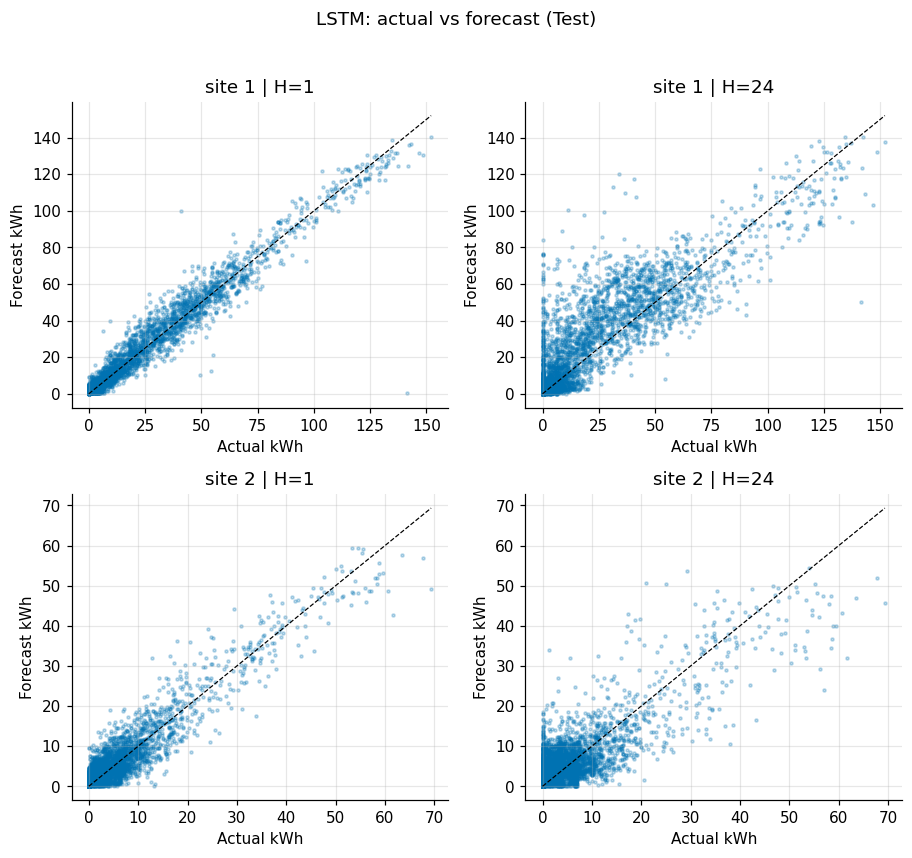

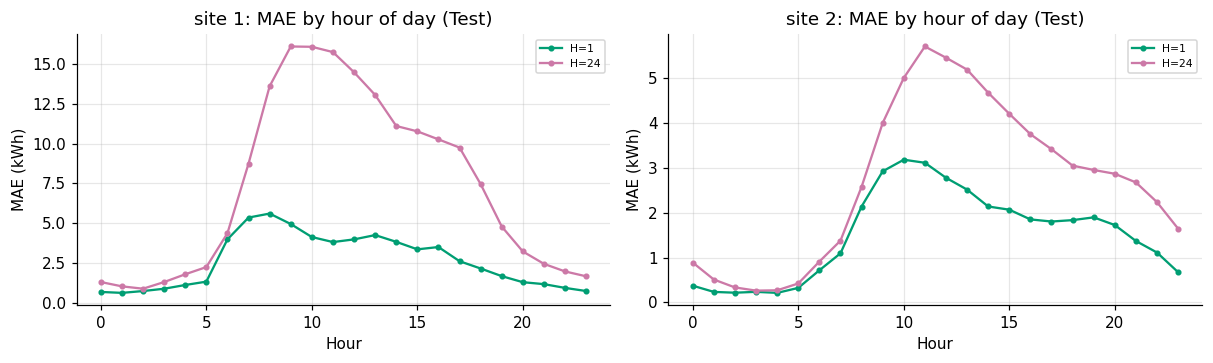

In [8]:
frames, BEST, HIST_LOG = [], {}, {}
for site in SITES:
    for h in HORIZONS:
        D = DATA[(site, h)]; p = dict(STUDIES[(site, h)].best_params); P1 = {s: [] for s in ['train', 'val', 'test']}; eps = []
        for sd in range(N_SEEDS):                                           # ---- run 1: Train, early stop on Val
            m, hist = fit_rnn('lstm', p, D['train'], D['val'], FINAL_EPOCHS, PATIENCE, SEED + sd, final=True)
            eps.append(int(np.argmin(hist.history['val_mae'])) + 1)
            for s in P1: P1[s].append(pred_rnn(m, D[s], site))
            if sd == 0: HIST_LOG[(site, h)] = pd.DataFrame(hist.history); npar = m.count_params()
        for s in P1: frames.append(pred_frame(site, h, 'run1', s, D[s]['idx'], np.mean(P1[s], axis=0)))
        ep2 = int(max(3, round(float(np.median(eps)) * 1.15))); P2 = []
        for sd in range(N_SEEDS):                                           # ---- run 2: Train+Val, fixed epochs
            m, _ = fit_rnn('lstm', p, D['dev'], None, ep2, PATIENCE, SEED + sd)
            P2.append(pred_rnn(m, D['test'], site))
        frames.append(pred_frame(site, h, 'run2', 'test', D['test']['idx'], np.mean(P2, axis=0)))
        BEST[f'site{site}_H{h}'] = dict(**p, best_val_mae_kWh=STUDIES[(site, h)].best_value, run1_epochs=eps, run2_epochs=ep2, n_params=int(npar))
        print(f'site {site} | H={h} | run1 epochs {eps} | run2 epochs {ep2} | params {npar:,}')
PRED = pd.concat(frames, ignore_index=True)
RES, W = standard_report(PRED, extra_json={'best_hyperparameters': BEST, 'tuning': dict(library='optuna ' + optuna.__version__, sampler='TPE', n_trials=N_TRIALS,
        objective='Validation MAE (kWh/h), train -> val', tune_epochs=TUNE_EPOCHS, seeds=N_SEEDS), 'device': str(GPUS)})

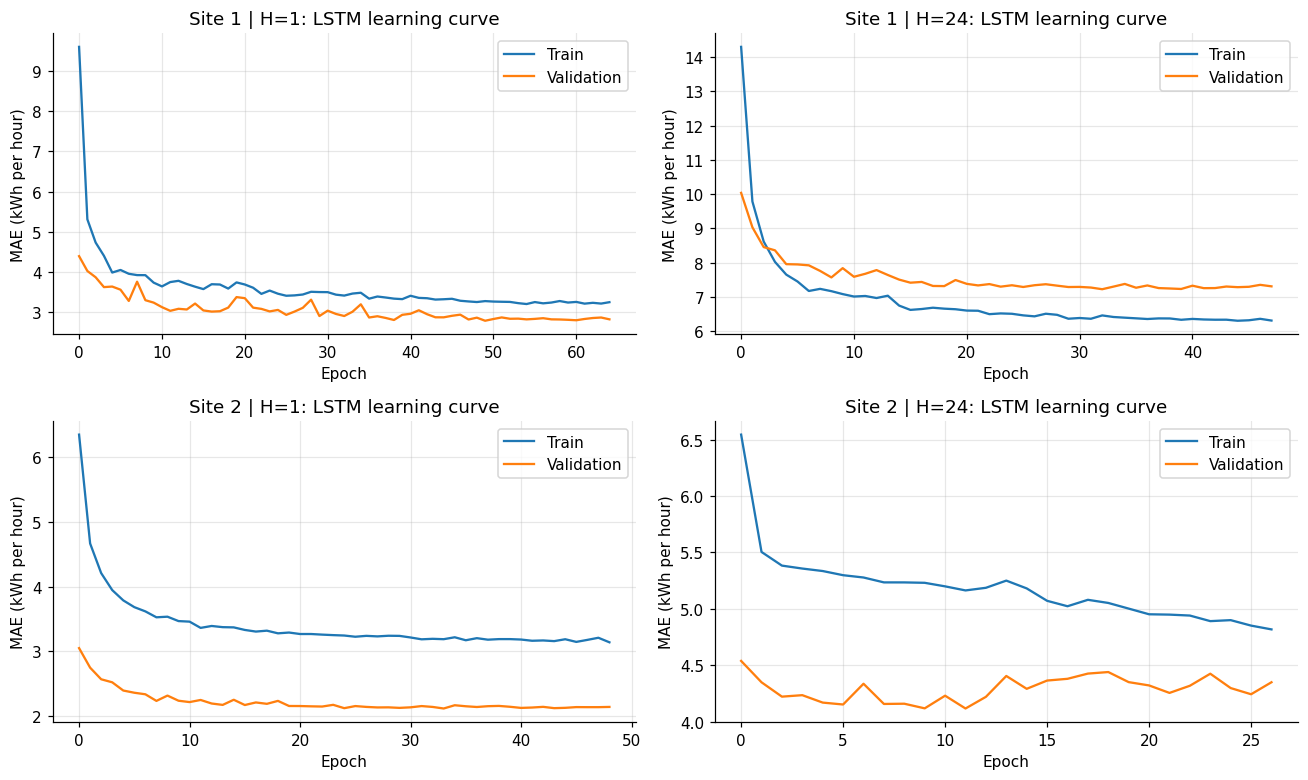

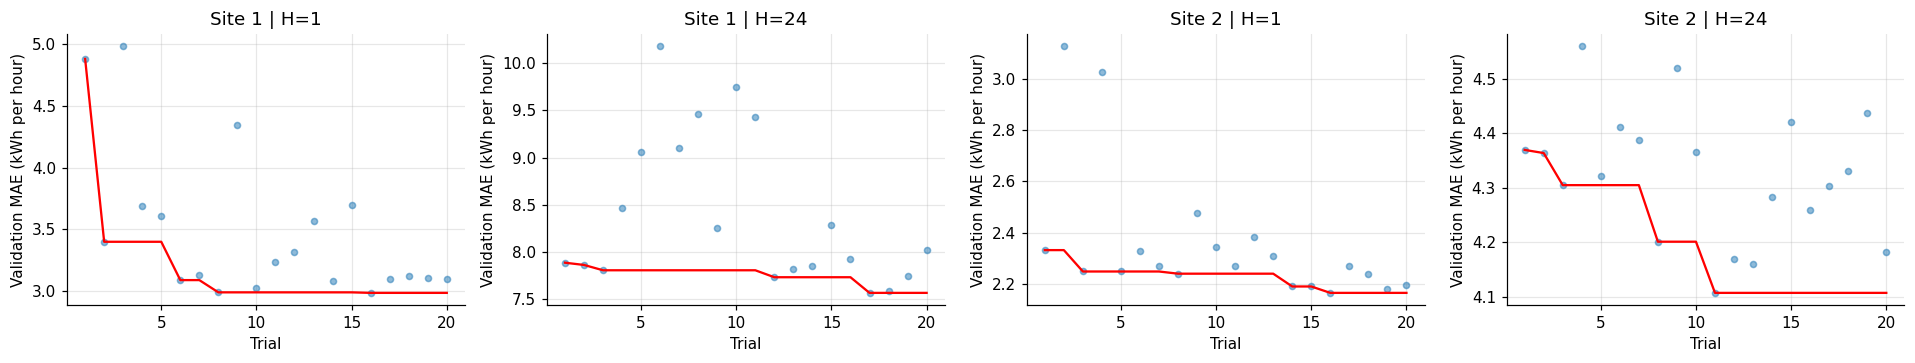

               site1_H1  site1_H24  site2_H1  site2_H24
weight_decay      0.414      0.292     0.141      0.009
dropout           0.262      0.021     0.242      0.079
units_1           0.221      0.106     0.000      0.539
loss              0.022      0.007     0.000      0.001
dense_units       0.021      0.109     0.136      0.112
learning_rate     0.016      0.131     0.233      0.114
units_0           0.016      0.160     0.159      0.090
n_layers          0.015      0.048     0.065      0.033
lookback          0.007      0.048     0.015      0.005
batch_size        0.006      0.018     0.004      0.018
bidirectional     0.000      0.059     0.005      0.001


In [9]:
fig, axs = plt.subplots(len(SITES), len(HORIZONS), figsize=(6 * len(HORIZONS), 3.6 * len(SITES)), squeeze=False)
for i, site in enumerate(SITES):
    for j, h in enumerate(HORIZONS):
        hh = HIST_LOG[(site, h)]; sc = SCALE[site]['y']
        axs[i, j].plot(hh.mae * sc, label='Train'); axs[i, j].plot(hh.val_mae * sc, label='Validation')
        axs[i, j].set(title=f'Site {site} | H={h}: LSTM learning curve', xlabel='Epoch', ylabel='MAE (kWh per hour)'); axs[i, j].legend()
plt.tight_layout(); savefig('F4_learning_curves')
fig, axs = plt.subplots(1, len(SITES) * len(HORIZONS), figsize=(4.4 * len(SITES) * len(HORIZONS), 3.4), squeeze=False); j = 0
for site in SITES:
    for h in HORIZONS:
        v = np.array([x.value for x in STUDIES[(site, h)].trials if x.value is not None])
        axs[0, j].plot(range(1, len(v) + 1), v, 'o', alpha=.5, ms=4); axs[0, j].plot(range(1, len(v) + 1), np.minimum.accumulate(v), 'r-')
        axs[0, j].set(title=f'Site {site} | H={h}', xlabel='Trial', ylabel='Validation MAE (kWh per hour)'); j += 1
plt.tight_layout(); savefig('F5_optuna_history')
try:
    IMP = pd.concat([pd.Series(get_param_importances(STUDIES[k])).rename(f'site{k[0]}_H{k[1]}') for k in STUDIES], axis=1).fillna(0)
    IMP.to_csv(os.path.join(OUT_DIR, 'lstm_hp_importance.csv')); print(IMP.round(3).to_string())
except Exception as e: print('importance skipped:', e)